# Análisis de sismicidad de Colombia con el catálogo del USGS

**Cuaderno reproducible · catálogo USGS 2000–2024 · completitud y relación de Gutenberg-Richter**

+++ {"no-pdf": true}

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/scr-ungrd/cuadernos-reproducibles-crc003/blob/main/sismicidad-colombia.ipynb) [![Abrir en Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/scr-ungrd/cuadernos-reproducibles-crc003/main?filepath=sismicidad-colombia.ipynb)

+++

---

## Stack

```text
Herramienta principal: Python 3.11 con pandas, numpy, scipy, matplotlib y folium
Datos base:            Catálogo de eventos sísmicos del USGS (servicio web FDSN)
Periodo y área:        2000–2024; 5° S a 13° N y 82° O a 65° O; magnitud ≥ 3,0
Método:                magnitud de completitud (máximo de curvatura) y b de Aki-Utsu

Ejecución recomendada en Google Colab con runtime CPU.
La instalación de las dependencias toma unos minutos la primera vez.
```

Este cuaderno reproducible caracteriza la sismicidad de Colombia y su área de influencia con el catálogo global del Servicio Geológico de los Estados Unidos (USGS) para 2000–2024 y magnitud de 3,0 o más: 4 201 eventos en la descarga de noviembre de 2026. Estima la magnitud de completitud (Mc = 4,3) y el parámetro *b* de la relación de Gutenberg-Richter por máxima verosimilitud (1,06 ± 0,02, con 2 275 eventos por encima de Mc), y describe la distribución temporal, la profundidad focal (54,5 % de los eventos son superficiales y 45,5 % intermedios) y la variación estacional, con mapas interactivos de epicentros. Muestra también dos límites del catálogo: la caja de búsqueda incluye países vecinos, de modo que el mayor sismo del periodo (magnitud 7,8, en 2016) ocurrió en Ecuador, y el catálogo global tiene una completitud menor que el del Servicio Geológico Colombiano. El cuaderno sirve para aprender el método, no para un estudio de amenaza, y corre completo con datos abiertos y sin credenciales.

El código de análisis y los scripts de construcción están disponibles públicamente en https://github.com/scr-ungrd/cuadernos-reproducibles-crc003 bajo licencia MIT, y el texto y las figuras, bajo CC-BY-4.0. El catálogo proviene del servicio web FDSN de eventos del USGS (https://earthquake.usgs.gov/fdsnws/event/1/), de dominio público, y se descarga al ejecutar el cuaderno, sin registro ni clave. El USGS puede revisar magnitudes, por lo que las cifras pueden variar un poco al repetir la descarga.

- El catálogo USGS tiene 4 201 sismos de magnitud 3,0 o más en 2000–2024 en la caja de búsqueda, y 54,5 % son superficiales (hasta 70 km)
- La magnitud de completitud es 4,3, muy por encima del umbral de descarga de 3,0
- El parámetro *b* es 1,06 ± 0,02 por máxima verosimilitud; la regresión sobre la curva acumulada da 0,93
- La caja incluye países vecinos: el mayor sismo del catálogo (magnitud 7,8, abril de 2016) ocurrió en Ecuador
- Es un catálogo global: para un estudio de amenaza se debe usar el del Servicio Geológico Colombiano

(inicio-cuerpo)=
## 1. Introducción

Este cuaderno muestra cómo analizar el **catálogo sísmico de Colombia** con datos públicos del USGS a través de su servicio FDSN, sin registro ni clave. Es un cuaderno de ejemplo de la serie de Cuadernos Reproducibles de la UNGRD: descarga el catálogo, analiza su distribución temporal, estima la magnitud de completitud y la *b-value* de la relación de **Gutenberg-Richter**, explora la profundidad focal y crea mapas interactivos de epicentros con Folium.

Colombia se encuentra en la zona de convergencia de las **placas tectónicas de Nazca, Caribe y Sudamérica**, lo que la convierte en uno de los países con mayor actividad sísmica de América Latina. Esta condición explica la frecuencia y diversidad de sismos: desde eventos someros en la corteza continental hasta sismos profundos de subducción.

La caracterización estadística de la sismicidad —su tasa de ocurrencia, distribución de magnitudes y profundidades— es un insumo fundamental para el **Análisis Probabilista de Amenaza Sísmica (PSHA)**, que sustenta la norma sismoresistente colombiana (NSR-10) y los estudios de microzonificación.

:::{admonition} Datos utilizados
:class: note
**Fuente**: USGS Earthquake Hazards Program · FDSN Event Web Service  
**API**: `https://earthquake.usgs.gov/fdsnws/event/1/query`  
**Período**: 2000–2024  
**Cobertura**: Colombia y área de influencia (bounding box)  
**Magnitud mínima**: M ≥ 3.0  
**Licencia de datos**: Dominio público (U.S. Government Work)
:::

## 2. Instalación de Dependencias

Este cuaderno utiliza únicamente bibliotecas estándar del ecosistema científico Python. Para instalarlas en tu entorno local:

In [1]:
import sys

# ── Detección automática del entorno de ejecución ────────────────────────────
_ES_JUPYTERLITE = 'pyodide' in sys.modules
_ES_COLAB       = 'google.colab' in sys.modules

if _ES_JUPYTERLITE:
    import micropip
    await micropip.install(['pyodide-http', 'folium', 'scipy'])
    import pyodide_http
    pyodide_http.patch_all()
    print('✅ Entorno: JupyterLite (navegador)')

else:
    import subprocess
    paquetes = [
        'pandas<3.0.0',   # <3.0.0 por compatibilidad con bqplot y otros paquetes del entorno
        'numpy',
        'matplotlib',
        'folium',
        'requests',
        'scipy',
    ]
    print('📦 Verificando e instalando dependencias...')
    subprocess.run(
        [sys.executable, '-m', 'pip', 'install', '-q'] + paquetes,
        check=True
    )
    entorno = 'Google Colab' if _ES_COLAB else 'local / Binder'
    print(f'✅ Entorno: {entorno}')

📦 Verificando e instalando dependencias...


✅ Entorno: local / Binder


In [2]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import folium
from folium.plugins import MarkerCluster, HeatMap
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Configuración de estilos
plt.rcParams.update({
    'figure.dpi': 120,
    'font.family': 'sans-serif',
    'axes.spines.top': False,
    'axes.spines.right': False,
})
UNGRD_BLUE = '#0154a5'
UNGRD_ACCENT = '#2563eb'

print('✅ Dependencias cargadas correctamente')

✅ Dependencias cargadas correctamente


## 3. Descarga del Catálogo Sísmico desde la API del USGS

Usamos la **FDSN Event Web Service** del USGS, que no requiere autenticación. El bounding box cubre el territorio colombiano incluyendo el área de influencia de las principales zonas de subducción.

:::{warning}
La caja de búsqueda (5° S a 13° N y 82° O a 65° O) **no coincide con las fronteras del país**: incluye parte de Ecuador, Perú, Venezuela, Brasil y Panamá, de modo que algunos de los sismos mayores del listado no son colombianos (la columna `lugar` indica dónde ocurrió cada uno). Además, el USGS es un catálogo **global**; el del Servicio Geológico Colombiano (SGC) tiene más estaciones locales y una magnitud de completitud menor. Este cuaderno sirve para aprender el método, no para un estudio de amenaza.
:::

In [3]:
# Parámetros de consulta — puedes modificar estos valores
PARAMS = {
    'format':     'csv',
    'starttime':  '2000-01-01',
    'endtime':    '2024-12-31',
    'minlatitude':  -5.0,   # sur de Colombia
    'maxlatitude':  13.0,   # norte (incluye Caribe)
    'minlongitude': -82.0,  # oeste (Pacífico)
    'maxlongitude': -65.0,  # este (Orinoquía)
    'minmagnitude': 3.0,
    'orderby': 'time',
}

API_URL = 'https://earthquake.usgs.gov/fdsnws/event/1/query'

print('🌐 Descargando catálogo sísmico del USGS...')
print(f"   Período: {PARAMS['starttime']} → {PARAMS['endtime']}")
print(f"   Área: Colombia y área de influencia")
print(f"   Magnitud mínima: M ≥ {PARAMS['minmagnitude']}")

response = requests.get(API_URL, params=PARAMS, timeout=120)
response.raise_for_status()

from io import StringIO
df_raw = pd.read_csv(StringIO(response.text))
print(f"\n✅ Descarga completa: {len(df_raw):,} eventos sísmicos")

🌐 Descargando catálogo sísmico del USGS...
   Período: 2000-01-01 → 2024-12-31
   Área: Colombia y área de influencia
   Magnitud mínima: M ≥ 3.0



✅ Descarga completa: 4,201 eventos sísmicos


## 4. Limpieza y Preparación de los Datos

Se seleccionan las columnas relevantes, se convierte el tiempo a fecha y se clasifica cada sismo por su profundidad focal: superficial (hasta 70 km), intermedia (70 a 300 km) y profunda (más de 300 km). La {numref}`Tabla %s <tbl-descriptivas>` resume la magnitud y la profundidad del catálogo y la {numref}`Tabla %s <tbl-clases-prof>` la distribución por clase de profundidad (ver código en la versión web).

In [4]:
# Seleccionar y renombrar columnas relevantes
df = df_raw[['time', 'latitude', 'longitude', 'depth', 'mag', 'magType', 'place']].copy()
df.columns = ['tiempo', 'latitud', 'longitud', 'profundidad_km', 'magnitud', 'tipo_mag', 'lugar']

# Convertir tiempo a datetime
df['tiempo'] = pd.to_datetime(df['tiempo'], utc=True)
df['año']    = df['tiempo'].dt.year
df['mes']    = df['tiempo'].dt.month

# Eliminar registros sin magnitud o profundidad
df = df.dropna(subset=['magnitud', 'profundidad_km', 'latitud', 'longitud'])

# Clasificación de profundidad focal
def clasificar_profundidad(d):
    if d <= 70:   return 'Superficial (≤ 70 km)'
    elif d <= 300: return 'Intermedia (70–300 km)'
    else:          return 'Profunda (> 300 km)'

df['clase_profundidad'] = df['profundidad_km'].apply(clasificar_profundidad)

print(f"Registros válidos: {len(df):,}")
print(f"\nEstadísticas descriptivas:")

Registros válidos: 4,201

Estadísticas descriptivas:


In [5]:
_d = df[['magnitud', 'profundidad_km']].describe()
_t = _d.apply(lambda col: col.map(lambda v: f'{v:.2f}'.replace('.', ',')))
_t.loc['count'] = [f'{int(v):,}'.replace(',', ' ') for v in _d.loc['count']]
_t = _t.rename(columns={'magnitud': 'Magnitud', 'profundidad_km': 'Profundidad (km)'}).rename(index={'count': 'Eventos', 'mean': 'Media', 'std': 'Desv. estándar', 'min': 'Mínimo', 'max': 'Máximo'})
_t

,Magnitud,Profundidad (km)
Eventos,4 201,4 201
Media,"4,42","81,09"
Desv. estándar,"0,46","64,43"
Mínimo,"3,00","0,00"
25%,"4,20","20,38"
50%,"4,40","55,60"
75%,"4,60","152,41"
Máximo,"7,80","436,50"


:::{table} Estadísticas descriptivas de la magnitud y la profundidad focal del catálogo USGS descargado.
:label: tbl-descriptivas

```{embed} #cell-tbl-descriptivas
:remove-input: true
```

25 %, 50 % y 75 % son los percentiles correspondientes; la magnitud es de tipos mezclados (Mw, Mb, Ml, entre otros).
:::

In [6]:
_cl = df['clase_profundidad'].value_counts().rename('Eventos').to_frame()
_cl['% del total'] = [f'{v:.1f}'.replace('.', ',') for v in _cl['Eventos'] / len(df) * 100]
_cl['Eventos'] = [f'{v:,}'.replace(',', ' ') for v in _cl['Eventos']]
_cl.index.name = 'Clase de profundidad'
_cl

,Eventos,% del total
Clase de profundidad,,
Superficial (≤ 70 km),2 290,"54,5"
Intermedia (70–300 km),1 910,"45,5"
Profunda (> 300 km),1,"0,0"


:::{table} Distribución del catálogo por clase de profundidad focal.
:label: tbl-clases-prof

```{embed} #cell-tbl-clases-prof
:remove-input: true
```

Superficial, hasta 70 km; intermedia, de 70 a 300 km; profunda, más de 300 km.
:::

## 5. Distribución Temporal de la Sismicidad

Analizamos la evolución anual de la actividad sísmica. Un catálogo cambia con la red de estaciones (más estaciones detectan más sismos pequeños) y los años con sismos grandes concentran réplicas, por lo que la tasa anual **no** debe leerse como un cambio real de la actividad sin revisar antes la completitud (sección 6).

La {numref}`Figura %s <fig-temporal>` muestra el número de eventos por año y la magnitud máxima anual (ver código en la versión web).

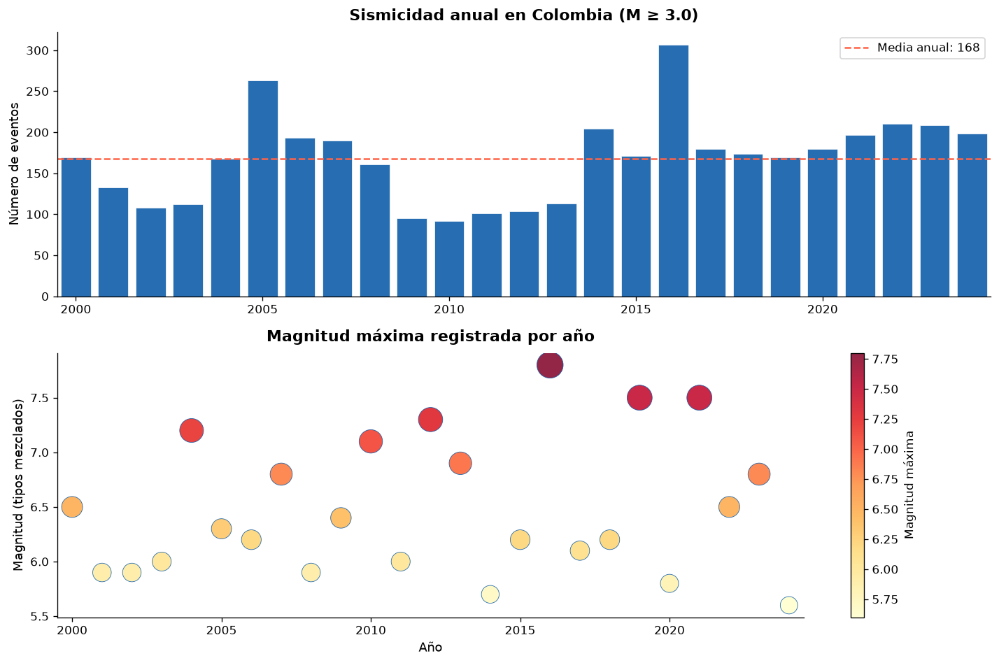

Figura guardada: sismicidad_temporal.png


In [7]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

# --- Panel superior: sismos por año ---
sismos_anuales = df.groupby('año').size().reset_index(name='conteo')
axes[0].bar(sismos_anuales['año'], sismos_anuales['conteo'],
            color=UNGRD_BLUE, alpha=0.85, edgecolor='white', linewidth=0.5)
axes[0].axhline(sismos_anuales['conteo'].mean(), color='tomato',
                linestyle='--', linewidth=1.5, label=f"Media anual: {sismos_anuales['conteo'].mean():.0f}")
axes[0].set_title('Sismicidad anual en Colombia (M ≥ 3.0)', fontsize=13, fontweight='bold', pad=10)
axes[0].set_ylabel('Número de eventos', fontsize=11)
axes[0].legend(fontsize=10)
axes[0].set_xlim(1999.5, 2024.5)

# --- Panel inferior: magnitud máxima por año ---
mag_anual = df.groupby('año')['magnitud'].max().reset_index()
sc = axes[1].scatter(mag_anual['año'], mag_anual['magnitud'],
                     s=mag_anual['magnitud']**2.5 * 3, c=mag_anual['magnitud'],
                     cmap='YlOrRd', alpha=0.85, edgecolors=UNGRD_BLUE, linewidths=0.5)
plt.colorbar(sc, ax=axes[1], label='Magnitud máxima')
axes[1].set_title('Magnitud máxima registrada por año', fontsize=13, fontweight='bold', pad=10)
axes[1].set_ylabel('Magnitud (tipos mezclados)', fontsize=11)
axes[1].set_xlabel('Año', fontsize=11)
axes[1].set_xlim(1999.5, 2024.5)

plt.tight_layout()
plt.savefig('sismicidad_temporal.png', bbox_inches='tight', dpi=150)
plt.show()
print('Figura guardada: sismicidad_temporal.png')

:::{figure} sismicidad_temporal.png
:label: fig-temporal
:align: center
Distribución temporal de la sismicidad en Colombia (M ≥ 3.0), 2000–2024. Panel superior: número de eventos anuales con la media del período (línea roja). Panel inferior: magnitud máxima registrada por año.
:::

## 6. Relación de Gutenberg-Richter

La relación de **Gutenberg-Richter** ($\log_{10} N = a - b \cdot M$) describe la distribución de magnitudes de una región sísmica: $N$ es el número de sismos de magnitud mayor o igual a $M$. El parámetro *b* (típicamente cercano a 1,0) indica la proporción entre sismos pequeños y grandes: una *b* más alta significa más sismos pequeños por cada grande. Es uno de los insumos fundamentales del Análisis Probabilista de Amenaza Sísmica (PSHA).

El ajuste solo es válido por encima de la **magnitud de completitud** $M_c$, la menor magnitud desde la cual el catálogo registra todos los eventos. La estimamos con el método del máximo de la curvatura (el intervalo de magnitud con más eventos) y calculamos *b* con **máxima verosimilitud** (Aki, 1965; Utsu, 1966), el estimador más usado, con su error estándar. Como comparación, se calcula también por regresión sobre la curva acumulada, que suele sesgar el resultado porque los puntos acumulados no son independientes.

La {numref}`Figura %s <fig-gr>` presenta el ajuste y la magnitud de completitud (ver código en la versión web).

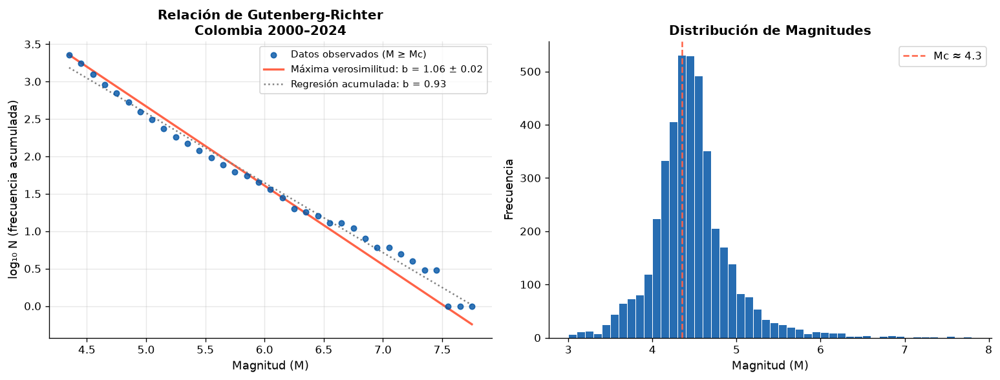

Parámetros Gutenberg-Richter para el catálogo USGS:
   Magnitud de completitud (máximo de curvatura): Mc = 4.3  (n = 2,275 eventos con M ≥ Mc)
   b por máxima verosimilitud: 1.06 ± 0.02   (valor típico ≈ 1,0)
   b por regresión acumulada:  0.93  (R² = 0.991)


In [8]:
def calcular_gutenberg_richter(magnitudes, bin_size=0.1):
    """Estima Mc (máximo de curvatura) y b (máxima verosimilitud de Aki-Utsu y regresión acumulada)."""
    mags = np.asarray(magnitudes)
    bins = np.round(np.arange(mags.min(), mags.max() + bin_size, bin_size), 2)
    conteo, bordes = np.histogram(mags, bins=bins)
    centros = bordes[:-1] + bin_size / 2
    mc = centros[np.argmax(conteo)]                       # magnitud de completitud

    sel = mags[mags >= mc]                                # solo por encima de Mc
    b_ml = np.log10(np.e) / (sel.mean() - (mc - bin_size / 2))
    b_se = b_ml / np.sqrt(len(sel))

    m_ac = centros[centros >= mc]
    acum = np.array([(sel >= m).sum() for m in m_ac])
    ok = acum > 0
    pendiente, intercepto, r, _, _ = stats.linregress(m_ac[ok], np.log10(acum[ok]))
    return dict(mc=mc, n=len(sel), b_ml=b_ml, b_se=b_se, b_ls=-pendiente, a_ls=intercepto,
                r2=r**2, m=m_ac[ok], log_n=np.log10(acum[ok]), centros=centros, conteo=conteo)


gr = calcular_gutenberg_richter(df['magnitud'])
b = gr['b_ml']

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --- Gráfico G-R (por encima de Mc) ---
axes[0].scatter(gr['m'], gr['log_n'], color=UNGRD_BLUE, s=25, alpha=0.8,
                label='Datos observados (M ≥ Mc)', zorder=3)
log_n_mc = gr['log_n'][0]
axes[0].plot(gr['m'], log_n_mc - gr['b_ml'] * (gr['m'] - gr['m'][0]), color='tomato', linewidth=2,
             label=f"Máxima verosimilitud: b = {gr['b_ml']:.2f} ± {gr['b_se']:.2f}")
axes[0].plot(gr['m'], gr['a_ls'] - gr['b_ls'] * gr['m'], color='gray', linewidth=1.5, linestyle=':',
             label=f"Regresión acumulada: b = {gr['b_ls']:.2f}")
axes[0].set_xlabel('Magnitud (M)', fontsize=11)
axes[0].set_ylabel('log₁₀ N (frecuencia acumulada)', fontsize=11)
axes[0].set_title('Relación de Gutenberg-Richter\nColombia 2000–2024', fontsize=12, fontweight='bold')
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.3)

# --- Histograma de magnitudes con Mc ---
axes[1].bar(gr['centros'], gr['conteo'], width=0.09, color=UNGRD_BLUE, alpha=0.85)
axes[1].axvline(gr['mc'], color='tomato', linestyle='--', linewidth=1.5, label=f"Mc ≈ {gr['mc']:.1f}")
axes[1].set_xlabel('Magnitud (M)', fontsize=11)
axes[1].set_ylabel('Frecuencia', fontsize=11)
axes[1].set_title('Distribución de Magnitudes', fontsize=12, fontweight='bold')
axes[1].legend(fontsize=10)

plt.tight_layout()
plt.savefig('gutenberg_richter.png', bbox_inches='tight', dpi=150)
plt.show()

print('Parámetros Gutenberg-Richter para el catálogo USGS:')
print(f"   Magnitud de completitud (máximo de curvatura): Mc = {gr['mc']:.1f}  (n = {gr['n']:,} eventos con M ≥ Mc)")
print(f"   b por máxima verosimilitud: {gr['b_ml']:.2f} ± {gr['b_se']:.2f}   (valor típico ≈ 1,0)")
print(f"   b por regresión acumulada:  {gr['b_ls']:.2f}  (R² = {gr['r2']:.3f})")

:::{figure} gutenberg_richter.png
:label: fig-gr
:align: center
Relación de Gutenberg-Richter para el catálogo USGS de Colombia y su área de influencia, 2000–2024. Izquierda: frecuencia acumulada por encima de la magnitud de completitud, con *b* por máxima verosimilitud (línea roja) y por regresión (línea punteada). Derecha: histograma de magnitudes y magnitud de completitud (Mc).
:::

Si $M_c$ es mayor que 3,0, los sismos entre 3,0 y $M_c$ **no** forman parte del ajuste: incluirlos subestima *b*. Para una tasa de recurrencia se prefiere la máxima verosimilitud, con $\beta = b \ln 10$.

## 7. Análisis de Profundidad Focal

La profundidad focal de un sismo determina en buena medida su radio de afectación y el tipo de daños que puede generar. Colombia presenta una distribución de profundidades amplia y variada, reflejo de los distintos regímenes tectónicos que confluyen en el territorio.

La {numref}`Figura %s <fig-profundidad>` muestra el histograma de profundidades y su relación con la magnitud (ver código en la versión web).

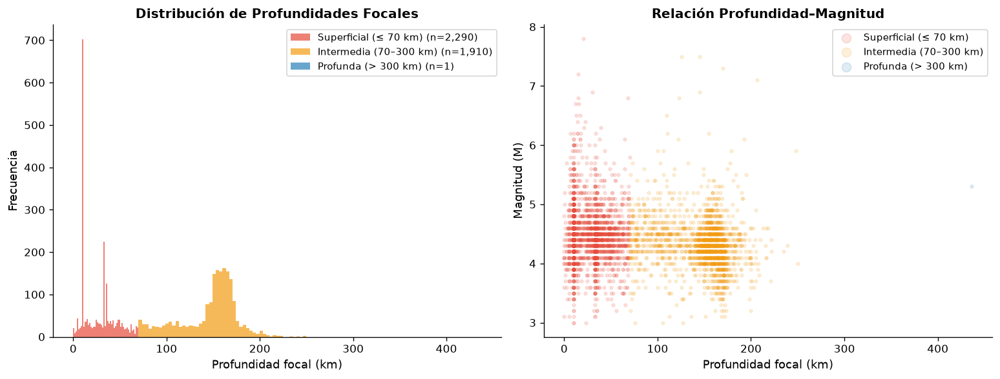

In [9]:
COLORES_PROF = {
    'Superficial (≤ 70 km)':    '#e74c3c',
    'Intermedia (70–300 km)':   '#f39c12',
    'Profunda (> 300 km)':      '#2980b9',
}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --- Histograma de profundidades ---
for clase, color in COLORES_PROF.items():
    subset = df[df['clase_profundidad'] == clase]
    axes[0].hist(subset['profundidad_km'], bins=50, alpha=0.7, color=color,
                 label=f'{clase} (n={len(subset):,})', edgecolor='none')
axes[0].set_xlabel('Profundidad focal (km)', fontsize=11)
axes[0].set_ylabel('Frecuencia', fontsize=11)
axes[0].set_title('Distribución de Profundidades Focales', fontsize=12, fontweight='bold')
axes[0].legend(fontsize=9)

# --- Magnitud vs. Profundidad ---
for clase, color in COLORES_PROF.items():
    subset = df[df['clase_profundidad'] == clase]
    axes[1].scatter(subset['profundidad_km'], subset['magnitud'],
                    alpha=0.15, s=8, color=color, label=clase)
axes[1].set_xlabel('Profundidad focal (km)', fontsize=11)
axes[1].set_ylabel('Magnitud (M)', fontsize=11)
axes[1].set_title('Relación Profundidad–Magnitud', fontsize=12, fontweight='bold')
axes[1].legend(fontsize=9, markerscale=3)

plt.tight_layout()
plt.savefig('profundidad_focal.png', bbox_inches='tight', dpi=150)
plt.show()

:::{figure} profundidad_focal.png
:label: fig-profundidad
:align: center
Distribución de profundidades focales en Colombia 2000–2024. Izquierda: histograma por clase de profundidad (superficial, intermedia, profunda). Derecha: relación profundidad–magnitud por clase.
:::

## 8. Sismos Más Significativos

Identificamos los eventos de mayor magnitud del período analizado y los contextualizamos dentro del marco tectónico de Colombia. La {numref}`Tabla %s <tbl-top>` lista los 15 mayores sismos del catálogo con el lugar de cada uno (ver código en la versión web); varios ocurrieron fuera de Colombia.

In [10]:
# Top 15 eventos por magnitud
top_sismos = df.nlargest(15, 'magnitud')[['tiempo', 'magnitud', 'profundidad_km',
                                           'clase_profundidad', 'latitud', 'longitud', 'lugar']]
top_sismos['tiempo'] = top_sismos['tiempo'].dt.strftime('%Y-%m-%d %H:%M UTC')
top_sismos = top_sismos.reset_index(drop=True)
top_sismos.index += 1
top_sismos.columns = ['Fecha/Hora', 'Magnitud', 'Prof. (km)', 'Clase', 'Lat', 'Lon', 'Lugar']

In [11]:
top_sismos

,Fecha/Hora,Magnitud,Prof. (km),Clase,Lat,Lon,Lugar
1,2016-04-16 23:58 UTC,7.8,20.59,Superficial (≤ 70 km),0.3819,-79.9218,"27 km SSE of Muisne, Ecuador"
2,2021-11-28 10:52 UTC,7.5,126.00,Intermedia (70–300 km),-4.4667,-76.8126,"43 km NNW of Barranca, Peru"
3,2019-02-22 10:17 UTC,7.5,145.00,Intermedia (70–300 km),-2.1862,-77.0505,"115 km ESE of Palora, Ecuador"
4,2012-09-30 16:31 UTC,7.3,170.00,Intermedia (70–300 km),1.9290,-76.3620,"11 km WNW of San Agustín, Colombia"
5,2004-11-15 09:06 UTC,7.2,15.00,Superficial (≤ 70 km),4.6950,-77.5080,"32 km SSW of Pizarro, Colombia"
6,2010-08-12 11:54 UTC,7.1,206.70,Intermedia (70–300 km),-1.2660,-77.3060,Ecuador
7,2016-05-18 16:46 UTC,6.9,29.95,Superficial (≤ 70 km),0.4947,-79.6160,"24 km NW of Rosa Zarate, Ecuador"
8,2013-02-09 14:16 UTC,6.9,145.00,Intermedia (70–300 km),1.1350,-77.3930,"2 km NNE of Yacuanquer, Colombia"
9,2023-03-18 17:12 UTC,6.8,68.00,Superficial (≤ 70 km),-2.7834,-79.8518,"14 km NNW of Baláo, Ecuador"
10,2007-11-16 03:13 UTC,6.8,122.90,Intermedia (70–300 km),-2.3120,-77.8380,"30 km E of Macas, Ecuador"


:::{table} Los 15 mayores sismos del catálogo USGS en la caja de búsqueda, 2000–2024.
:label: tbl-top

```{embed} #cell-tbl-top
:remove-input: true
```

Lat y Lon, latitud y longitud del epicentro en grados; la columna Lugar es la descripción del USGS e indica el país.
:::

## 9. Mapa Interactivo de Epicentros

El siguiente mapa muestra la distribución espacial de los epicentros. El tamaño de cada círculo es proporcional a la magnitud y el color indica la profundidad focal. El mapa interactivo de la versión web permite acercarse a cada región y consultar los datos de cada evento. No se reproduce en el PDF (ver código en la versión web).

In [12]:
def color_por_profundidad(profundidad):
    if profundidad <= 70:    return '#e74c3c'   # rojo — superficial
    elif profundidad <= 300: return '#f39c12'   # naranja — intermedia
    else:                    return '#2980b9'   # azul — profunda

# Centrar mapa en Colombia
mapa = folium.Map(
    location=[4.5, -74.0],
    zoom_start=5,
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}',
    attr='Tiles © Esri — Esri, DeLorme, NAVTEQ',
    max_native_zoom=12,
    max_zoom=12
)

# Usar solo M >= 4.0 para no sobrecargar el mapa
df_mapa = df[df['magnitud'] >= 4.0].copy()

# Capa de calor (heatmap) de todos los eventos M >= 3.0
heat_data = df[['latitud', 'longitud', 'magnitud']].values.tolist()
HeatMap(heat_data, name='Densidad sísmica (M ≥ 3.0)',
        radius=6, blur=8, max_zoom=8).add_to(mapa)

# Capa de marcadores para M >= 4.0
cluster = MarkerCluster(name='Epicentros M ≥ 4.0')
for _, row in df_mapa.iterrows():
    radio = max(3, row['magnitud'] ** 2.2 * 0.5)
    popup_txt = (
        f"<b>Magnitud:</b> M {row['magnitud']:.1f}<br>"
        f"<b>Profundidad:</b> {row['profundidad_km']:.0f} km ({row['clase_profundidad']})<br>"
        f"<b>Fecha:</b> {str(row['tiempo'])[:10]}<br>"
        f"<b>Lugar:</b> {row['lugar']}"
    )
    folium.CircleMarker(
        location=[row['latitud'], row['longitud']],
        radius=radio,
        color=color_por_profundidad(row['profundidad_km']),
        fill=True, fill_opacity=0.65, weight=0.5,
        popup=folium.Popup(popup_txt, max_width=280),
        tooltip=f"M {row['magnitud']:.1f}"
    ).add_to(cluster)

cluster.add_to(mapa)

# Leyenda
leyenda_html = """
<div style="position:fixed; bottom:30px; left:30px; z-index:1000;
     background:white; padding:12px 16px; border-radius:8px;
     box-shadow:0 2px 8px rgba(0,0,0,0.2); font-size:12px; font-family:sans-serif;">
  <b>Profundidad focal</b><br>
  <span style='color:#e74c3c;'>●</span> Superficial ≤ 70 km<br>
  <span style='color:#f39c12;'>●</span> Intermedia 70–300 km<br>
  <span style='color:#2980b9;'>●</span> Profunda > 300 km<br>
  <hr style='margin:6px 0; border-color:#eee;'>
  <small>Tamaño ∝ Magnitud · Catálogo USGS 2000–2024</small>
</div>
"""
mapa.get_root().html.add_child(folium.Element(leyenda_html))
folium.LayerControl().add_to(mapa)

# Guardar y mostrar
mapa.save('mapa_sismicidad_colombia.html')
print(f'✅ Mapa generado con {len(df_mapa):,} epicentros (M ≥ 4.0)')
print('   Abre mapa_sismicidad_colombia.html para visualización interactiva')
_html = mapa._repr_html_().replace('Make this Notebook Trusted to load map: File -> Trust Notebook', '')
from IPython.display import HTML
HTML(_html)

✅ Mapa generado con 3,765 epicentros (M ≥ 4.0)
   Abre mapa_sismicidad_colombia.html para visualización interactiva


## 10. Animación Temporal de la Sismicidad

El siguiente mapa anima la sismicidad de Colombia durante el período 2000–2024, evento por evento, con una ventana visible de tres meses. Cada círculo representa un evento M ≥ 4.0; su tamaño es proporcional a la magnitud y el color indica la profundidad focal. Usa el control deslizante o el botón ▶ para reproducir la secuencia. No se reproduce en el PDF (ver código en la versión web).

In [13]:
from folium.plugins import TimestampedGeoJson

# Filtrar eventos M >= 4.0 para reducir el volumen de la animación
df_anim = df[df['magnitud'] >= 4.0].copy()
df_anim = df_anim.sort_values('tiempo').reset_index(drop=True)

# Construir features GeoJSON con timestamps individuales
features = []
for _, row in df_anim.iterrows():
    mag  = row['magnitud']
    prof = row['profundidad_km']
    color = color_por_profundidad(prof)
    feature = {
        'type': 'Feature',
        'geometry': {
            'type': 'Point',
            'coordinates': [row['longitud'], row['latitud']]
        },
        'properties': {
            'time': row['tiempo'].strftime('%Y-%m-%dT%H:%M:%S'),
            'popup': (
                f"<b>M {mag:.1f}</b><br>"
                f"Profundidad: {prof:.0f} km ({row['clase_profundidad']})<br>"
                f"Fecha: {str(row['tiempo'])[:10]}<br>"
                f"{row['lugar']}"
            ),
            'style': {'weight': 0},
            'icon': 'circle',
            'iconstyle': {
                'fillColor': color,
                'fillOpacity': 0.75,
                'stroke': True,
                'color': '#222',
                'weight': 0.4,
                'radius': max(4, mag ** 2.2 * 0.55)
            }
        }
    }
    features.append(feature)

# Mapa base con fondo oscuro para mejor contraste
mapa_anim = folium.Map(
    location=[4.5, -74.0],
    zoom_start=5,
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Dark_Gray_Base/MapServer/tile/{z}/{y}/{x}',
    attr='Tiles © Esri — Esri, DeLorme, NAVTEQ',
    max_native_zoom=12,
    max_zoom=12
)

# Capa animada temporal — período mensual, ventana de 3 meses visible
TimestampedGeoJson(
    {'type': 'FeatureCollection', 'features': features},
    period='P1M',
    duration='P3M',
    transition_time=400,
    loop=False,
    auto_play=False,
    add_last_point=True,
    date_options='YYYY-MM-DD'
).add_to(mapa_anim)

# Leyenda
leyenda_anim = """
<div style='position:fixed; bottom:30px; left:30px; z-index:1000;
     background:rgba(20,20,20,0.85); color:#eee; padding:12px 16px;
     border-radius:8px; box-shadow:0 2px 8px rgba(0,0,0,0.5);
     font-size:12px; font-family:sans-serif;'>
  <b>Profundidad focal</b><br>
  <span style='color:#e74c3c;'>●</span> Superficial ≤ 70 km<br>
  <span style='color:#f39c12;'>●</span> Intermedia 70–300 km<br>
  <span style='color:#2980b9;'>●</span> Profunda > 300 km<br>
  <hr style='margin:6px 0; border-color:#555;'>
  <small>Tamaño ∝ Magnitud · M ≥ 4.0 · 2000–2024</small>
</div>
"""
mapa_anim.get_root().html.add_child(folium.Element(leyenda_anim))

# El complemento de folium deja la línea de tiempo con un solo instante; se fija con las fechas de los sismos
_js = """
window.addEventListener('load', function () {
  var m = %s;
  m.eachLayer(function (l) {
    if (l._availableTimes && l._availableTimes.length > 1) {
      var t = Array.from(new Set(l._availableTimes)).sort(function (a, b) { return a - b; });
      m.timeDimension.setAvailableTimes(t, 'replace');
      m.timeDimension.setCurrentTimeIndex(0);
    }
  });
});
""" % mapa_anim.get_name()
mapa_anim.get_root().script.add_child(folium.Element(_js))

mapa_anim.save('mapa_animado_sismicidad.html')
print(f'✅ Animación generada: {len(df_anim):,} eventos M ≥ 4.0 · {len(features)} instantes (uno por sismo)')
_html = mapa_anim._repr_html_().replace('Make this Notebook Trusted to load map: File -> Trust Notebook', '')
from IPython.display import HTML
HTML(_html)

✅ Animación generada: 3,765 eventos M ≥ 4.0 · 3765 instantes (uno por sismo)


## 11. Variación Estacional de la Sismicidad

La sismicidad tectónica no debería mostrar una variación estacional marcada. Este análisis revisa si el número de eventos y la magnitud media cambian por mes. Las diferencias que aparezcan **no** prueban un efecto del clima: los sismos grandes generan réplicas que concentran eventos en meses específicos, y el catálogo no está declustered (sin separar réplicas). Una relación con la lluvia requeriría eliminar las réplicas y una prueba estadística. La {numref}`Figura %s <fig-estacional>` muestra el resultado (ver código en la versión web).

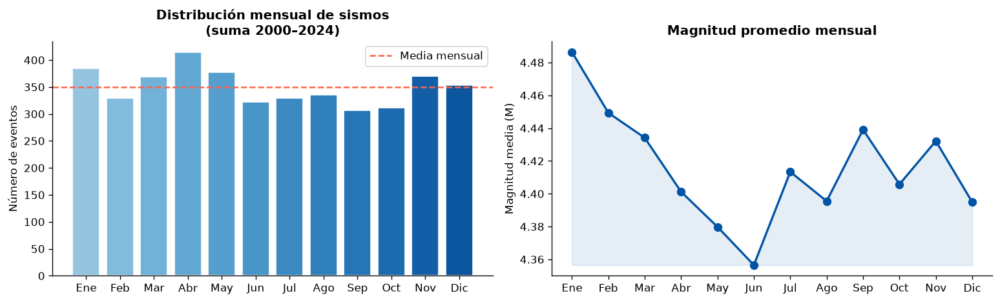

In [14]:
meses_nombres = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun',
                 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# --- Sismos por mes (todos los años) ---
por_mes = df.groupby('mes').size().reset_index(name='conteo')
axes[0].bar(por_mes['mes'], por_mes['conteo'],
            color=[plt.cm.Blues(0.4 + 0.5 * i / 12) for i in range(12)],
            edgecolor='white')
axes[0].axhline(por_mes['conteo'].mean(), color='tomato',
                linestyle='--', linewidth=1.5, label='Media mensual')
axes[0].set_xticks(range(1, 13))
axes[0].set_xticklabels(meses_nombres)
axes[0].set_title('Distribución mensual de sismos\n(suma 2000–2024)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Número de eventos')
axes[0].legend()

# --- Magnitud media mensual ---
mag_mes = df.groupby('mes')['magnitud'].mean()
axes[1].plot(mag_mes.index, mag_mes.values, 'o-',
             color=UNGRD_BLUE, linewidth=2, markersize=7)
axes[1].fill_between(mag_mes.index, mag_mes.values,
                     mag_mes.values.min(), alpha=0.1, color=UNGRD_BLUE)
axes[1].set_xticks(range(1, 13))
axes[1].set_xticklabels(meses_nombres)
axes[1].set_title('Magnitud promedio mensual', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Magnitud media (M)')

plt.tight_layout()
plt.savefig('variacion_estacional.png', bbox_inches='tight', dpi=150)
plt.show()

:::{figure} variacion_estacional.png
:label: fig-estacional
:align: center
Variación estacional de la sismicidad en Colombia. Izquierda: distribución mensual del número de eventos (suma 2000–2024). Derecha: magnitud promedio mensual.
:::

## 12. Resumen del Análisis y Próximos Pasos

Este cuaderno realizó un análisis exploratorio de la sismicidad de Colombia usando únicamente datos públicos y herramientas de código abierto. Los resultados ilustran el carácter **multiamenaza** del territorio y la riqueza de información disponible para análisis de riesgo sísmico.

El resumen numérico del catálogo se imprime en la celda siguiente (ver código en la versión web).

In [15]:
print('=' * 60)
print('  RESUMEN — SISMICIDAD DE COLOMBIA 2000–2024')
print('=' * 60)
print(f'  Total de eventos M ≥ 3.0:     {len(df):,}')
print(f'  Magnitud máxima registrada:   M {df["magnitud"].max():.1f}')
print(f'  Magnitud media:               M {df["magnitud"].mean():.2f}')
print(f'  Profundidad media:            {df["profundidad_km"].mean():.1f} km')
print(f'  Eventos superficiales (≤70):  {(df["profundidad_km"]<=70).sum():,} ({(df["profundidad_km"]<=70).mean()*100:.1f}%)')
print(f'  Período de análisis:          2000–2024 (25 años)')
print(f"  Magnitud de completitud (Mc): M {gr['mc']:.1f}")
print(f"  b-value (máx. verosimilitud): {gr['b_ml']:.2f} ± {gr['b_se']:.2f}")
print('=' * 60)
print()
print('Archivos generados:')
print('  📊 sismicidad_temporal.png')
print('  📊 gutenberg_richter.png')
print('  📊 profundidad_focal.png')
print('  📊 variacion_estacional.png')
print('  🗺️  mapa_sismicidad_colombia.html')

  RESUMEN — SISMICIDAD DE COLOMBIA 2000–2024
  Total de eventos M ≥ 3.0:     4,201
  Magnitud máxima registrada:   M 7.8
  Magnitud media:               M 4.42
  Profundidad media:            81.1 km
  Eventos superficiales (≤70):  2,290 (54.5%)
  Período de análisis:          2000–2024 (25 años)
  Magnitud de completitud (Mc): M 4.3
  b-value (máx. verosimilitud): 1.06 ± 0.02

Archivos generados:
  📊 sismicidad_temporal.png
  📊 gutenberg_richter.png
  📊 profundidad_focal.png
  📊 variacion_estacional.png
  🗺️  mapa_sismicidad_colombia.html


### 12.1 Próximos pasos y extensiones

El cuaderno puede extenderse de varias maneras. La {numref}`Tabla %s <tbl-extensiones>` resume algunas ideas para contribuciones a la plataforma.

:::{table} Extensiones propuestas del cuaderno.
:label: tbl-extensiones

| Extensión | Descripción | Complejidad |
|---|---|---|
| **Microzonificación** | Cruzar catálogo sísmico con datos de suelo y NSR-10 para análisis local | Media |
| **PSHA simplificado** | Implementar curvas de peligro sísmico con OpenQuake para ciudades principales | Alta |
| **Enjambres sísmicos** | Detección automática de enjambres con algoritmos de clustering (DBSCAN) | Media |
| **Relación lluvia-sismo** | Correlación entre precipitación intensa y sismicidad inducida | Media |
| **Alerta temprana** | Simular un sistema de detección en tiempo real con la API del USGS | Alta |
| **ML para clasificación** | Clasificar tipos de sismo con aprendizaje automático | Alta |

PSHA, análisis probabilista de amenaza sísmica; NSR-10, Reglamento Colombiano de Construcción Sismo Resistente.
:::

## 13. Referencias

1. USGS Earthquake Hazards Program. *FDSN Event Web Service*. https://earthquake.usgs.gov/fdsnws/event/1/
2. Servicio Geológico Colombiano. *Catálogo de Sismicidad de Colombia*. https://www.sgc.gov.co
3. Aki, K. (1965). Maximum likelihood estimate of *b* in the formula log N = a − bM and its confidence limits. *Bulletin of the Earthquake Research Institute*, 43, 237–239. Utsu, T. (1966). A statistical significance test of the difference in b-value between two earthquake groups. *Journal of Physics of the Earth*, 14, 37–40.
4. Gutenberg, B. & Richter, C.F. (1944). Frequency of earthquakes in California. *Bulletin of the Seismological Society of America*, 34(4), 185–188.
5. UNGRD (2019). *Atlas de Riesgo de Colombia: revelando los desastres latentes*. Unidad Nacional para la Gestión del Riesgo de Desastres.
6. UNDRR-ROAS (2024). *Inteligencia artificial para la reducción del riesgo de desastres en América Latina y el Caribe*.

*Plataforma de Análisis de Riesgos — Subdirección para el Conocimiento del Riesgo · UNGRD*  
*Licencia: Creative Commons BY 4.0 · Código: MIT License*